**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: Operaciones de Aprendizaje Automatizado**

Tecnológico de Monterrey


*   NOMBRE: - Fernando Arango Gaviria
*   MATRÍCULA: - A01797660

# **DATA WRANLING**

El Objetivo, es realizar un proceso de limpieza y EDA para el dataset previsto: room-ocupation-estimation.

In [57]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [58]:
import os
DIR = "/content/drive/MyDrive/Maestria/Operaciones de ML/Ejercicio_1/Data Wrangling/room-occupancy-estimation"
os.chdir(DIR)

In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from scipy import stats

**Obtención de la Base y Primera revisión general de la información**

In [60]:
room_occupation = pd.read_csv('modified.csv')
room_occupation

,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count,mixed_type_col
0,2017/12/22,10:49:41,24.94,345.75,24.56,25.38,121.0,34.0,53.0,40.0,0.08,0.19,0.06,0.06,390.0,0.769230769231,0.0,0.0,1.0,599
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121.0,33.0,53.0,40.0,0.93,0.05,0.06,0.06,390.0,0.646153846154,0.0,0.0,1.0,NaN
2,2017/12/22,10:50:42,25.0,24.75,24.5,25.44,121.0,34.0,53.0,40.0,0.43,0.11,0.08,0.06,390.0,0.519230769231,0.0,0.0,1.0,unknown
3,2017/12/22,10:51:13,25.0,24.75,24.56,25.44,121.0,34.0,53.0,40.0,0.41,0.1,0.1,0.09,390.0,0.388461538462,0.0,0.0,1.0,584
4,2017/12/22,10:51:44,25.0,24.75,24.56,25.44,121.0,34.0,54.0,40.0,0.18,0.06,0.06,0.06,390.0,0.253846153846,0.0,0.0,1.0,bad
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10326,2017/12/23,11:51:18,25.31,25.31,invalid,25.88,120.0,36.0,65.0,46.0,1.67,0.66,0.68,0.21,360.0,0.0346153846154,0.0,0.0,1.0,332
10327,2017/12/23,18:44:53,26.25,26.38,25.94,26.31,117.0,19.0,183.0,7.0,0.32,0.07,0.27,0.08,1065.0,2.06538461538,0.0,1.0,2.0,935
10328,2017/12/26,08:58:47,25.06,25.06,24.63,25.25,6.0,6.0,32.0,21.0,0.08,970.05,0.07,0.1,350.0,0.0,0.0,0.0,0.0,339
10329,2018/01/11,06:59:09,25.06,25.06,24.5,25.19,0.0,0.0,1.0,1.0,0.08,0.05,0.05,0.09,345.0,0.0,0.0,0.0,0.0,bad


In [61]:
room_occupation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10331 entries, 0 to 10330
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Date                  10241 non-null  object
 1   Time                  10230 non-null  object
 2   S1_Temp               10216 non-null  object
 3   S2_Temp               10203 non-null  object
 4   S3_Temp               10207 non-null  object
 5   S4_Temp               10221 non-null  object
 6   S1_Light              10217 non-null  object
 7   S2_Light              10209 non-null  object
 8   S3_Light              10200 non-null  object
 9   S4_Light              10213 non-null  object
 10  S1_Sound              10221 non-null  object
 11  S2_Sound              10216 non-null  object
 12  S3_Sound              10228 non-null  object
 13  S4_Sound              10236 non-null  object
 14  S5_CO2                10210 non-null  object
 15  S5_CO2_Slope          10220 non-null

In [62]:
print("DIMENSIONES DEL DATASET")
print(f"Filas: {room_occupation.shape[0]:,}, Columnas: {room_occupation.shape[1]}")

print("\n2. PRIMERAS FILAS (HEAD)")
display(room_occupation.head(3))

print("\n3. CONTEO DE DUPLICADOS EXACTOS")
print(f"Duplicados encontrados: {room_occupation.duplicated().sum()}")

DIMENSIONES DEL DATASET
Filas: 10,331, Columnas: 20

2. PRIMERAS FILAS (HEAD)


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count,mixed_type_col
0,2017/12/22,10:49:41,24.94,345.75,24.56,25.38,121.0,34.0,53.0,40.0,0.08,0.19,0.06,0.06,390.0,0.769230769231,0.0,0.0,1.0,599
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121.0,33.0,53.0,40.0,0.93,0.05,0.06,0.06,390.0,0.646153846154,0.0,0.0,1.0,NaN
2,2017/12/22,10:50:42,25.0,24.75,24.5,25.44,121.0,34.0,53.0,40.0,0.43,0.11,0.08,0.06,390.0,0.519230769231,0.0,0.0,1.0,unknown



3. CONTEO DE DUPLICADOS EXACTOS
Duplicados encontrados: 1


Información General encontrada:

* Base con 10,331 entradas
* Total de 20 columnas
* Aunque se tienen columnas de Fecha, Hora, y Datos numericos, todas las columnas son de tipo Object (Ninguna tiene 100% sus datos correctos)
* Ninguna columna tienen los 10,331 registros
* Se tiene una fila duplicada en su totalidad

**Revisión detallada de la Data de las columnas**

Revisar:
* Valores Nulos
* Valores Unicos

In [63]:
# Revisión de valores nulos y valores no convertibles
print("CONTEO DE VALORES NULOS POR COLUMNA")
print(room_occupation.isnull().sum())

print("\nMUESTRA DE VALORES ÚNICOS EN mixed_type_col")
if 'mixed_type_col' in room_occupation.columns:
    print(room_occupation['mixed_type_col'].value_counts(dropna=False).head(10))

print("\nREVISION DE TEXTO EN LA COLUMNA NUMÉRICA S1_Temp")
# Se valida que valores dan error al pasarlos a numérico
non_numeric_s1 = pd.to_numeric(room_occupation['S1_Temp'], errors='coerce').isna() & room_occupation['S1_Temp'].notna()
print(f"Filas en S1_Temp con texto no numérico: {non_numeric_s1.sum()}")
if non_numeric_s1.sum() > 0:
    print("Ejemplos de valores no numéricos en S1_Temp:")
    print(room_occupation.loc[non_numeric_s1, 'S1_Temp'].head(5))

CONTEO DE VALORES NULOS POR COLUMNA
Date                      90
Time                     101
S1_Temp                  115
S2_Temp                  128
S3_Temp                  124
S4_Temp                  110
S1_Light                 114
S2_Light                 122
S3_Light                 131
S4_Light                 118
S1_Sound                 110
S2_Sound                 115
S3_Sound                 103
S4_Sound                  95
S5_CO2                   121
S5_CO2_Slope             111
S6_PIR                   103
S7_PIR                   116
Room_Occupancy_Count     132
mixed_type_col          1054
dtype: int64

MUESTRA DE VALORES ÚNICOS EN mixed_type_col
mixed_type_col
bad        1068
unknown    1056
NaN        1054
786          16
957          16
194          15
214          15
359          15
277          15
146          15
Name: count, dtype: int64

REVISION DE TEXTO EN LA COLUMNA NUMÉRICA S1_Temp
Filas en S1_Temp con texto no numérico: 42
Ejemplos de valores no numéricos

* Todos las columnas tienen datos faltantes entre 90 y 132
* La última columna sobresale con una cantidad de faltantes mayor a 1,000
* Esta última columna tiene una gran cantidad de datos en 'Unknown', 'NaN' y 'bad'
* En una revisión rapida, la primer columna numerica, muestra datos de texto por lo que se comprueba por que es una columna tipo Object


**Limpieza de datos**

* Eliminar duplicados
* Conversion a Datos Numericos
* Limpieza en Categoricos

In [64]:
# Copiar la base para iniciar con la limpieza de los datos (Invalidos, conversión a numericos y eliminar duplicados)
df_clean = room_occupation.copy()

# Eliminar la linea duplicada
df_clean = df_clean.drop_duplicates()

# Definir lista de columnas que deben ser numéricas (todas excepto Date y Time, y mixed_type_col)
cols_to_numeric = [
    'S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp',
    'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light',
    'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound',
    'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR',
    'Room_Occupancy_Count'
]

# Forzar conversión a numérico: cualquier texto basura ('?', 'invalid', 'unknown', etc.) se convierte automáticamente en NaN
for col in cols_to_numeric:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# 'mixed_type_col', se convierte en categórica
df_clean['mixed_type_col'] = df_clean['mixed_type_col'].replace(['bad', 'unknown', 'NaN', 'nan'], np.nan)

In [65]:
print("INFORMACIÓN DESPUÉS DE LA CONVERSIÓN INICIAL")
df_clean.info()

print("\nNUEVO CONTEO DE NULOS")
print(df_clean[cols_to_numeric].isnull().sum())

INFORMACIÓN DESPUÉS DE LA CONVERSIÓN INICIAL
<class 'pandas.core.frame.DataFrame'>
Index: 10330 entries, 0 to 10330
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  10240 non-null  object 
 1   Time                  10229 non-null  object 
 2   S1_Temp               10173 non-null  float64
 3   S2_Temp               10167 non-null  float64
 4   S3_Temp               10169 non-null  float64
 5   S4_Temp               10178 non-null  float64
 6   S1_Light              10182 non-null  float64
 7   S2_Light              10168 non-null  float64
 8   S3_Light              10154 non-null  float64
 9   S4_Light              10186 non-null  float64
 10  S1_Sound              10184 non-null  float64
 11  S2_Sound              10174 non-null  float64
 12  S3_Sound              10192 non-null  float64
 13  S4_Sound              10203 non-null  float64
 14  S5_CO2                10171 no

**Definición de Estrategias para tratar la limpieza de datos**

A. Imputación de valores según la Mediana

B. Eliminación de datos faltantes

In [66]:
# Copia base limpia sin duplicados
df_base = df_clean.copy()

# ESTRATEGIA A: Imputación Estadística (Mediana)
df_estrategia_A = df_base.copy()
for col in cols_to_numeric:
    if col in df_estrategia_A.columns:
        mediana_val = df_estrategia_A[col].median()
        df_estrategia_A[col] = df_estrategia_A[col].fillna(mediana_val)

# Para las columnas de fecha/hora y texto, se incluye un valor por
df_estrategia_A['Date'] = df_estrategia_A['Date'].fillna(method='ffill') #Valor de la celda anterior
df_estrategia_A['Time'] = df_estrategia_A['Time'].fillna(method='ffill')
df_estrategia_A['mixed_type_col'] = df_estrategia_A['mixed_type_col'].fillna('desconocido') #Valor 'desconocido'


#ESTRATEGIA B: Eliminación
df_estrategia_B = df_base.dropna().copy()


print(f"Dimensiones Original (sin duplicado): {df_base.shape}")
print(f"\nDimensiones Estrategia A (Imputada): {df_estrategia_A.shape} (Conservó el 100% de filas)")
print(f"\nDimensiones Estrategia B (Eliminación): {df_estrategia_B.shape} (Filas restantes tras eliminar nulos)")

FilasBorradas = df_clean.shape[0]- df_estrategia_B.shape[0]
print(f"\nFilas Eliminadas en la Estrategia B: {FilasBorradas}")


Dimensiones Original (sin duplicado): (10330, 20)

Dimensiones Estrategia A (Imputada): (10330, 20) (Conservó el 100% de filas)

Dimensiones Estrategia B (Eliminación): (5461, 20) (Filas restantes tras eliminar nulos)

Filas Eliminadas en la Estrategia B: 4869


/tmp/ipykernel_871/3108373955.py:12: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_estrategia_A['Date'] = df_estrategia_A['Date'].fillna(method='ffill') #Valor de la celda anterior
/tmp/ipykernel_871/3108373955.py:13: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_estrategia_A['Time'] = df_estrategia_A['Time'].fillna(method='ffill')


In [67]:
#Cálculo de Métricas de Similitud (S1_Temp como ejemplo)


# Variable analizada como muestra representativa
col_test = 'S1_Temp'

# Datos limpios de nulos en la original
orig_clean_s1 = df_base[col_test].dropna()
imp_A_s1 = df_estrategia_A[col_test]
imp_B_s1 = df_estrategia_B[col_test]

# Comparar distribuciones: p-value alto indica que provienen de la misma distribución
ks_result_A = stats.ks_2samp(orig_clean_s1, imp_A_s1)
ks_result_B = stats.ks_2samp(orig_clean_s1, imp_B_s1)

print(f"PRUEBA COMPARANDO DISTRIBUCIONES para {col_test}")
print(f"Estrategia A (Imputada vs Original) -> Estadístico: {ks_result_A.statistic:.4f}, p-value: {ks_result_A.pvalue:.4f}")
print(f"Estrategia B (Eliminada vs Original)  -> Estadístico: {ks_result_B.statistic:.4f}, p-value: {ks_result_B.pvalue:.4f}")

# Diferencia de Medias
mean_orig = orig_clean_s1.mean()
std_orig = orig_clean_s1.std()

smd_A = abs(mean_orig - imp_A_s1.mean()) / std_orig
smd_B = abs(mean_orig - imp_B_s1.mean()) / std_orig

print(f"\nDIFERENCIA DE MEDIAS")
print(f"Estrategia A: {smd_A:.5f} (Idealmente cercano a 0)")
print(f"Estrategia B: {smd_B:.5f} (Idealmente cercano a 0)")

PRUEBA COMPARANDO DISTRIBUCIONES para S1_Temp
Estrategia A (Imputada vs Original) -> Estadístico: 0.0071, p-value: 0.9576
Estrategia B (Eliminada vs Original)  -> Estadístico: 0.0058, p-value: 0.9997

DIFERENCIA DE MEDIAS
Estrategia A: 0.00131 (Idealmente cercano a 0)
Estrategia B: 0.00564 (Idealmente cercano a 0)


Analisis de Resultados y comparativo de las dos estrategias:

* Eliminación de Valores.  En la estrategia B, se eliminan 4,869 valores (47% de los datos); mientras en la estrategia A se mantienen el 100% de los datos.
* Valores de p-value para las 2 estrategias muy cercanos a 1, lo que demuestra que distribuciones de los datos son estadisticamente similares con la base original.
* Valores de smd cercanas a 0; mostrando que los valores de las Medianas practicamente no se movieron


Considerando que las 2 estrategias mantienen estadisticamente los datos de forma correcta, es ideal utilizar la Estrategia A que no elimina datos.

**Revisión y Visualización de la información de la Estrategia A**

In [68]:
# Validación exhaustiva de valores y distribución por columna en df_estrategia_A

numeric_cols = [
    'S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp',
    'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light',
    'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound',
    'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR',
    'Room_Occupancy_Count'
]

# Resumen estadístico detallado
resumen_stats = df_estrategia_A[numeric_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]
resumen_stats['valores_unicos'] = [df_estrategia_A[col].nunique() for col in numeric_cols]


display(resumen_stats)

,count,mean,std,min,50%,max,valores_unicos
S1_Temp,10330.0,35.709761,121.045332,24.940000,25.38,3084.910000,131
S2_Temp,10330.0,35.651253,118.703340,24.750000,25.38,2546.720000,175
S3_Temp,10330.0,35.332843,122.072850,24.440000,25.00,2413.740000,136
S4_Temp,10330.0,34.156854,109.146593,24.940000,25.75,2553.880000,120
S1_Light,10330.0,35.160407,274.738926,0.000000,0.00,14308.000000,142
S2_Light,10330.0,33.133688,178.515762,0.000000,0.00,12168.000000,151
S3_Light,10330.0,44.111713,394.981558,0.000000,0.00,26208.000000,225
S4_Light,10330.0,20.227686,114.452203,0.000000,0.00,5041.000000,155
S1_Sound,10330.0,3.066697,43.125052,0.060000,0.08,993.070000,330
S2_Sound,10330.0,2.666932,40.673996,0.040000,0.05,970.050000,261


Analisis de la Información:

* Se puede ver claramente como se tiene una presencia de valores extremos (Outliers).  Ej en S1_Temp - La Mediana es 25; pero el valor maximo es superior a 3,000
* Diferencia entre Media y Mediana es significativo, lo que muestra una presencia importante de valores outliers
* Se tienen columnas con una alta concentración de datos en valores como 0.  Ejemplo S6_PIR, donde el valor minimo es 0 y el Q2 sigue siendo 0, pero tiene un valor maximo de 995

Analisis de Outliers

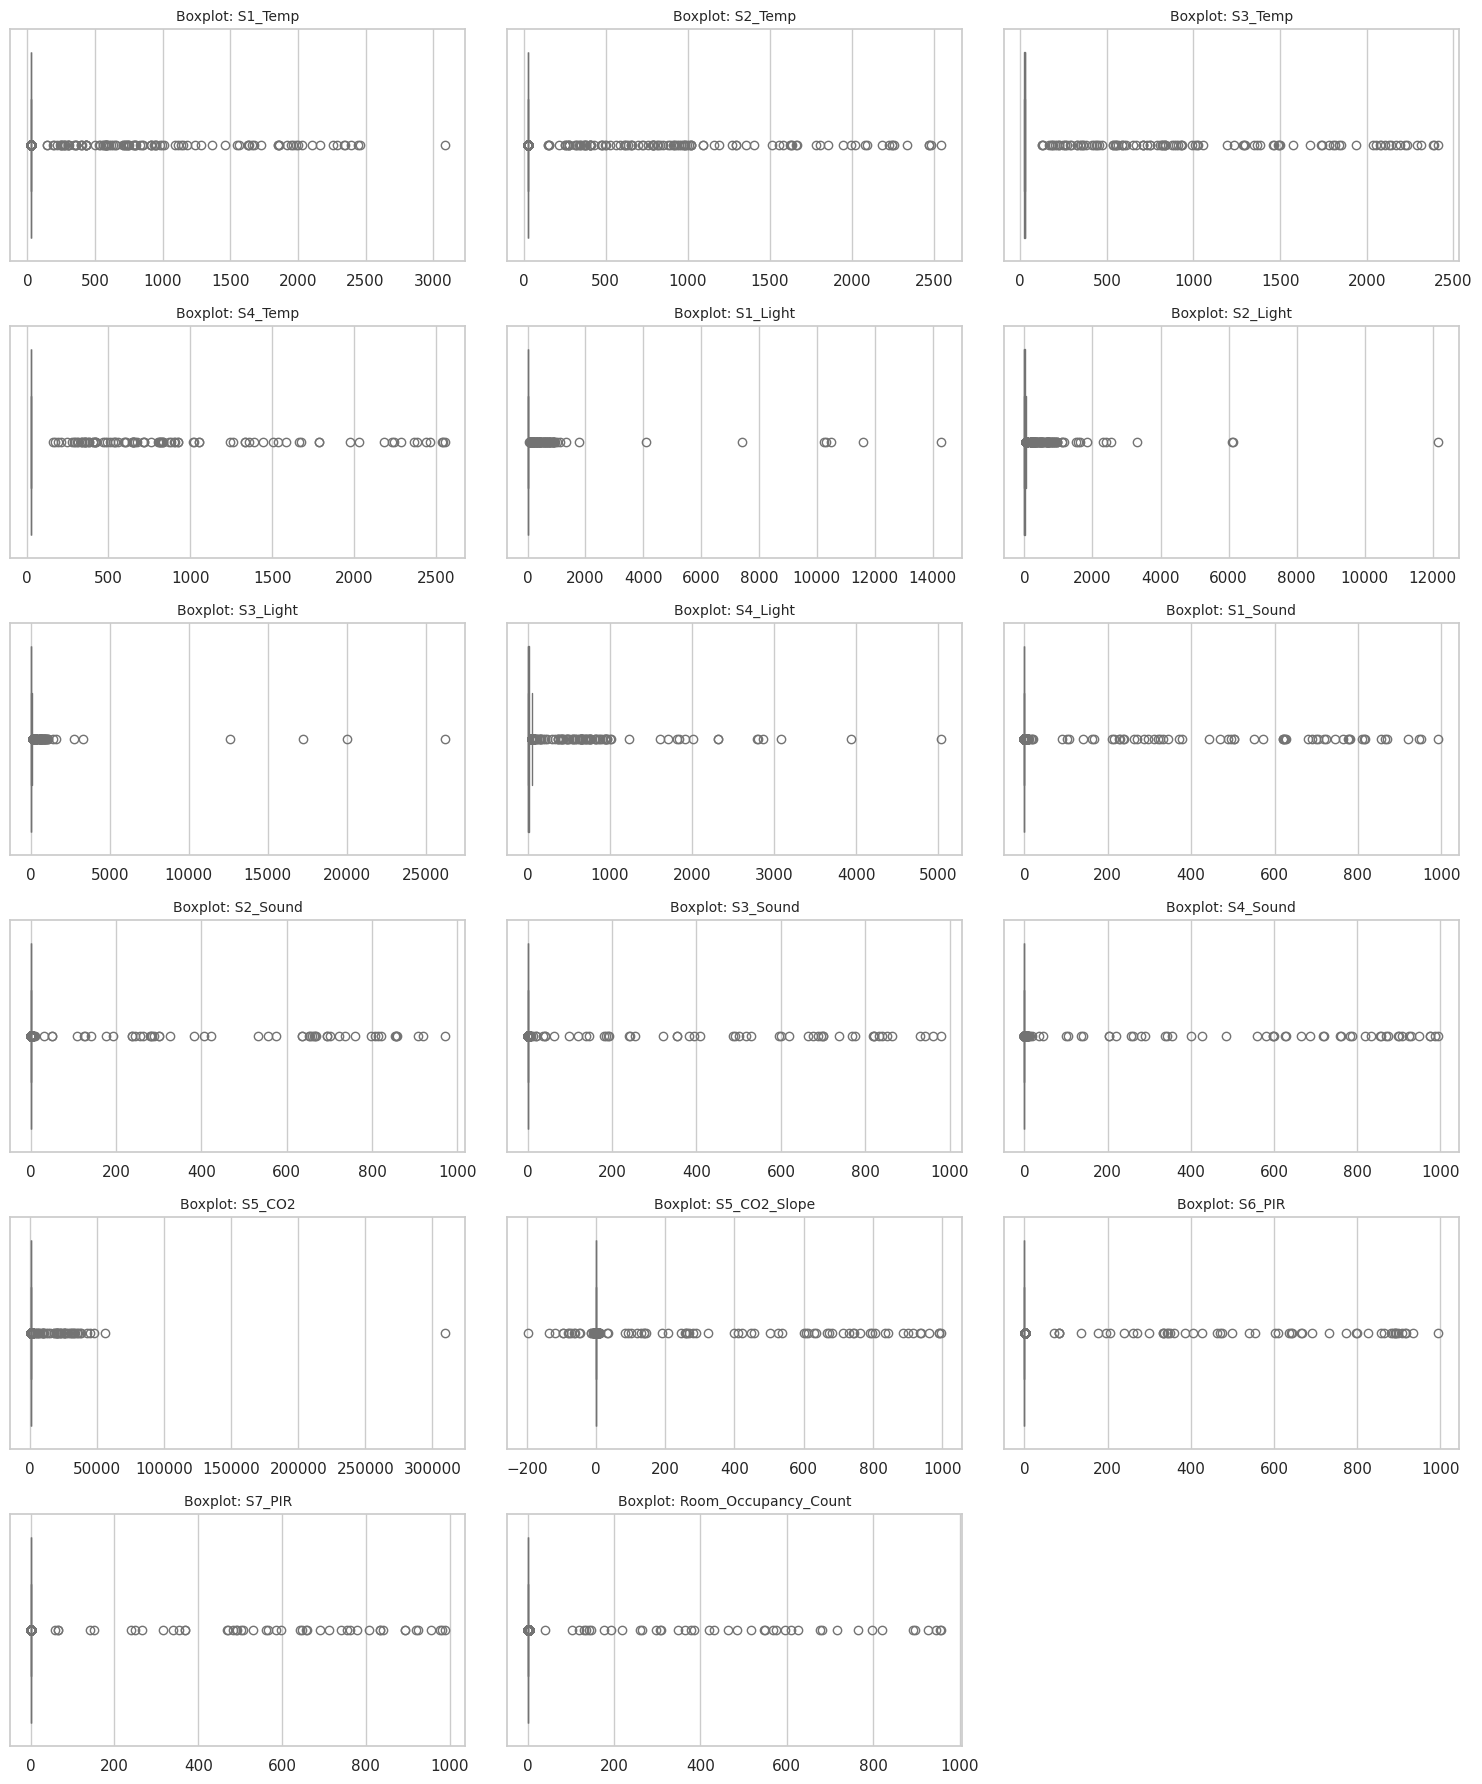

In [69]:
#Boxplots con representación de Outliers
fig, axes = plt.subplots(6, 3, figsize=(15, 18))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    if i < len(axes):
        sns.boxplot(x=df_estrategia_A[col], ax=axes[i], color='lightgreen')
        axes[i].set_title(f'Boxplot: {col}', fontsize=10)
        axes[i].set_xlabel('')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Las graficas muestran gran cantidad de Outliers en todas las columnas numericas

In [70]:
# Cantidad de Outliers por columna usando IQR
print("CONTEO DE OUTLIERS POR MÉTODO IQR (Estrategia A)\n")

for col in numeric_cols:
    q1 = df_estrategia_A[col].quantile(0.25)
    q3 = df_estrategia_A[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df_estrategia_A[(df_estrategia_A[col] < lower_bound) | (df_estrategia_A[col] > upper_bound)]
    print(f"Cantidad de outliers detectados en {col}: {len(outliers)}")

CONTEO DE OUTLIERS POR MÉTODO IQR (Estrategia A)

Cantidad de outliers detectados en S1_Temp: 276
Cantidad de outliers detectados en S2_Temp: 860
Cantidad de outliers detectados en S3_Temp: 107
Cantidad de outliers detectados en S4_Temp: 93
Cantidad de outliers detectados en S1_Light: 1792
Cantidad de outliers detectados en S2_Light: 1096
Cantidad de outliers detectados en S3_Light: 1000
Cantidad de outliers detectados en S4_Light: 613
Cantidad de outliers detectados en S1_Sound: 1889
Cantidad de outliers detectados en S2_Sound: 1795
Cantidad de outliers detectados en S3_Sound: 1762
Cantidad de outliers detectados en S4_Sound: 818
Cantidad de outliers detectados en S5_CO2: 1644
Cantidad de outliers detectados en S5_CO2_Slope: 4089
Cantidad de outliers detectados en S6_PIR: 969
Cantidad de outliers detectados en S7_PIR: 852
Cantidad de outliers detectados en Room_Occupancy_Count: 1934


Vemos una gran cantidad de Outliers por cada columna.

Validamos las frecuencias de los valores mas comunes para entender mejor por que algunas columnas tienen mas de 4,000 datos de Outliers

In [71]:
# Análisis de frecuencias: Identificar los valores más repetidos y su porcentaje en el dataset

resultados_frecuencias = []
total_filas = len(df_estrategia_A)

for col in numeric_cols:
    # Obtenemos el valor más frecuente (moda) y su conteo exacto
    val_mas_frecuente = df_estrategia_A[col].mode()[0]
    conteo = (df_estrategia_A[col] == val_mas_frecuente).sum()
    porcentaje = (conteo / total_filas) * 100

    resultados_frecuencias.append({
        'Columna': col,
        'Valor Más Frecuente': val_mas_frecuente,
        'Repeticiones': conteo,
        '% del Total de Filas': f"{porcentaje:.2f}%",
        'Valores Únicos': df_estrategia_A[col].nunique()
    })

df_freq_summary = pd.DataFrame(resultados_frecuencias)
display(df_freq_summary)

,Columna,Valor Más Frecuente,Repeticiones,% del Total de Filas,Valores Únicos
0,S1_Temp,25.38,1179,11.41%,131
1,S2_Temp,25.44,1377,13.33%,175
2,S3_Temp,24.56,805,7.79%,136
3,S4_Temp,25.75,880,8.52%,120
4,S1_Light,0.00,6004,58.12%,142
5,S2_Light,0.00,6007,58.15%,151
6,S3_Light,0.00,5768,55.84%,225
7,S4_Light,0.00,5751,55.67%,155
8,S1_Sound,0.07,3812,36.90%,330
9,S2_Sound,0.05,5935,57.45%,261


Comprobamos que algunas columnas tienen mas mas de 9,000 datos que son 0; por lo que cualquier valor que puede estar por arriba de 0 ya seria un Outlier.

Por este motivo, y para no utilizar el metodo IQR directamente, estaremos utilizando rangos permitidos de valores, para determinar los Outliers.

**Generación de Umbrales permitidos, Identificación de Outliers y Eliminación**

In [72]:
df_auditoria = df_estrategia_A.copy()

# Umbrales de dominio para todas las variables clave
umbrales = {
    'S1_Temp': (10, 50), 'S2_Temp': (10, 50), 'S3_Temp': (10, 50), 'S4_Temp': (10, 50),
    'S1_Light': (0, 2000), 'S2_Light': (0, 2000), 'S3_Light': (0, 2000), 'S4_Light': (0, 2000),
    'S1_Sound': (0, 100), 'S2_Sound': (0, 100), 'S3_Sound': (0, 100), 'S4_Sound': (0, 100),
    'S5_CO2': (300, 5000)
}

reporte_outliers = []
total_filas = len(df_auditoria)

for col, (min_val, max_val) in umbrales.items():
    # Identificamos cuántos valores caen fuera del rango físico lógico
    fuera_de_rango = (df_auditoria[col] < min_val) | (df_auditoria[col] > max_val)
    n_outliers = fuera_de_rango.sum()
    pct_outliers = (n_outliers / total_filas) * 100

    # Aplicamos el reemplazo a NaN
    df_auditoria.loc[fuera_de_rango, col] = np.nan

    reporte_outliers.append({
        'Columna': col,
        'Rango Válido (Min - Max)': f"{min_val} a {max_val}",
        'Valores Fuera de Rango': n_outliers,
        '% del Total de Datos': f"{pct_outliers:.4f}%"
    })

# Convertimos a DataFrame para una visualización limpia
df_reporte_final = pd.DataFrame(reporte_outliers)
display(df_reporte_final)

,Columna,Rango Válido (Min - Max),Valores Fuera de Rango,% del Total de Datos
0,S1_Temp,10 a 50,110,1.0649%
1,S2_Temp,10 a 50,109,1.0552%
2,S3_Temp,10 a 50,107,1.0358%
3,S4_Temp,10 a 50,93,0.9003%
4,S1_Light,0 a 2000,7,0.0678%
5,S2_Light,0 a 2000,7,0.0678%
6,S3_Light,0 a 2000,6,0.0581%
7,S4_Light,0 a 2000,9,0.0871%
8,S1_Sound,0 a 100,56,0.5421%
9,S2_Sound,0 a 100,49,0.4743%


Despues de Validar que esos valores dan numeros realistas y se pueden ejecutar eliminando un numero pequeño de datos; se procede con el ajuste a la base.

In [73]:
# Limpieza para las columnas numéricas
df_limpio_dominio = df_auditoria.copy()

# Reglas de dominio físicas para los diferentes sensores
#Temperaturas: 10°C a 50°C
for col in ['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp']:
    df_limpio_dominio[col] = df_limpio_dominio[col].apply(lambda x: np.nan if (x < 10 or x > 50) else x)

# Luz: 0 a 2000 lux
for col in ['S1_Light', 'S2_Light', 'S3_Light', 'S4_Light']:
    df_limpio_dominio[col] = df_limpio_dominio[col].apply(lambda x: np.nan if (x < 0 or x > 2000) else x)

#Sonido (dB / nivel relativo): 0 a 100
for col in ['S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound']:
    df_limpio_dominio[col] = df_limpio_dominio[col].apply(lambda x: np.nan if (x < 0 or x > 100) else x)

#CO2: 300 a 5000 ppm
for col in ['S5_CO2']:
    df_limpio_dominio[col] = df_limpio_dominio[col].apply(lambda x: np.nan if (x < 300 or x > 5000) else x)

#Rellenamos los nuevos nulos generados por el filtro usando la mediana de cada columna
for col in numeric_cols:
    med = df_limpio_dominio[col].median()
    df_limpio_dominio[col] = df_limpio_dominio[col].fillna(med)

print("¡Limpieza de dominio aplicada a todo el dataset con éxito!")

¡Limpieza de dominio aplicada a todo el dataset con éxito!


Se revisa la distribución de las columnas de Temperatura

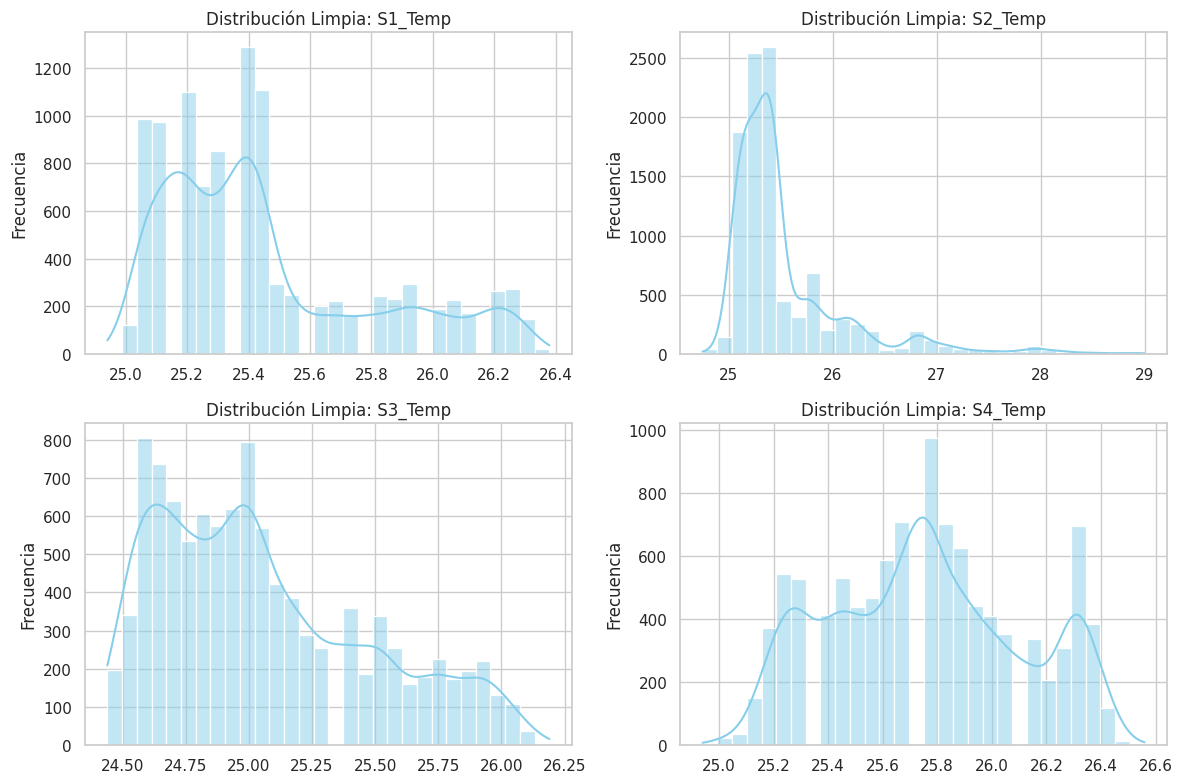

In [74]:
# Gráfica de Distribución para las Temperaturas limpias

sns.set_theme(style="whitegrid")
temp_cols = ['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(temp_cols):
    sns.histplot(df_limpio_dominio[col], kde=True, ax=axes[i], color='skyblue', bins=30)
    axes[i].set_title(f'Distribución Limpia: {col}')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

**Matriz de Correlación**

/tmp/ipykernel_871/3650045042.py:9: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  matriz_corr = df_limpio_dominio[cols_correlacion].method = df_limpio_dominio[cols_correlacion].corr(method='spearman')


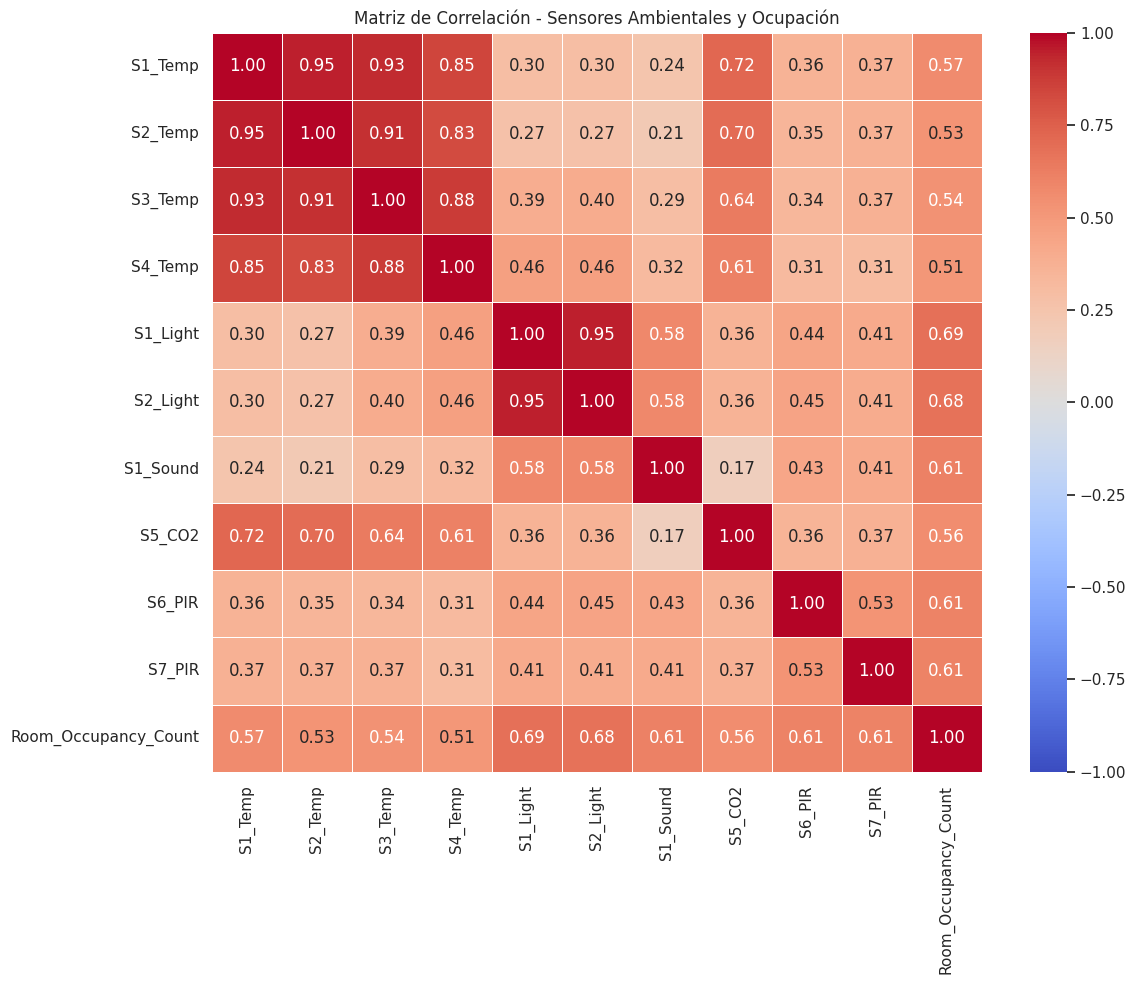

In [75]:

# Seleccionamos las columnas numéricas relevantes para la correlación
cols_correlacion = [
    'S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp',
    'S1_Light', 'S2_Light', 'S1_Sound', 'S5_CO2',
    'S6_PIR', 'S7_PIR', 'Room_Occupancy_Count'
]

# Calculamos la matriz de correlación para datos sesgados (Spearman)
matriz_corr = df_limpio_dominio[cols_correlacion].method = df_limpio_dominio[cols_correlacion].corr(method='spearman')

plt.figure(figsize=(12, 10))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlación - Sensores Ambientales y Ocupación', fontsize=12)
plt.tight_layout()
plt.show()